# 02 — Ingestion

**Tasks:** M1-T05 (pilot extraction) and M1-T06 (scaled extraction).

**Purpose:** a working, cached, provenance-tracked composite download; the real processing-unit (PU) cost of composites; and three data checks: cloud-mask holes over bright surfaces, a plausible reflectance range, and harmonisation across the 2022-01-25 processing-baseline change.

**Inputs:** `config/project.yaml` (`pilot` section), `config/aois.geojson`, `reports/results/m1_aoi_availability.csv`, `.env` (credentials).

**Outputs:** composites in `data/raw/<aoi_id>/` and statistics in `data/raw/stats/` (local, with provenance sidecars); `reports/results/m1_pilot_cost.csv`, `m1_pilot_qa.csv`, `m1_harmonisation.csv`; figures `reports/figures/m1_pilot_composite.png`, `m1_harmonisation.png`; a row in `data/api_usage_log.csv`.

**Run time:** under a minute; the first run makes a few API requests (plan printed below), and later runs use the cache and make none. The low-cloud filter test (one extra request) was added after the first pilot run.

In [56]:
%load_ext autoreload
%autoreload 2

import json
import logging
import platform
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
import rasterio
import sentinelhub

import desertification
from desertification.aoi import season_window, sub_window
from desertification.config import get_path, load_config, load_env
from desertification.feasibility import composite_pu, grid_shape, season_fraction
from desertification.features import ndvi
from desertification.extraction import append_log, build_plan, plan_status, run_plan, extraction_window
from desertification.ingest import download_composite, fetch_reflectance_stats, fetch_true_color
from desertification.qa import (
    compare_composites, harmonisation_ok, parse_stats_response, reflectance_summary, valid_count_summary,
    year_over_year_step,
)
from desertification.sh_client import missing_credentials
from desertification.usage import (
    append_usage, check_cap, estimate_process_pu, latest_balance, make_entry, read_usage_log,
)
from desertification.viz import plot_pilot_panels, plot_reflectance_series, plot_window_preview

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
cfg = load_config()
SEED = cfg["project"]["seed"]
rng = np.random.default_rng(SEED)
pilot = cfg["pilot"]
RESULTS, FIGURES = get_path(cfg, "results"), get_path(cfg, "figures")
print(f"Python {platform.python_version()} | desertification {desertification.__version__} | "
      f"sentinelhub {sentinelhub.__version__} | rasterio {rasterio.__version__}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Python 3.12.16 | desertification 0.1.0 | sentinelhub 3.12.1 | rasterio 1.5.2


## Pilot extraction (M1-T05)

**Design.** One AOI (`pilot.aoi_id`: the Aral Sea, the brightest surface and the one with the most acquisitions, so an upper bound on cost and a hard test for the cloud mask) and one season (the dry season of `pilot.year`). The request covers a centred 5 km × 5 km window rather than the full 20 km square: PU cost scales linearly with area (CDSE rules), and a full-size composite of the original design would exceed the whole setup-and-pilot budget.

Two designs, both 16-bit integer output (reflectance × 10 000; Decision log #45):

- **b10**: all 10 bands in `sentinel2.bands` + SCL (matches the current §7.2 schema);
- **c6**: only the six bands the nine indices need (B02 B03 B04 B08 B11 B12) + SCL.

Each composite is the per-pixel median of every cloud-free acquisition in the season (SCL mask from config), plus a count of valid acquisitions. A small Statistical API time series over the stable erg checks harmonisation.

**Quota.** The plan below prints the number of requests and the projected PU before anything is sent. Set `ALLOW_API_CALLS = True` only after it has been approved.

In [57]:
ALLOW_API_CALLS = False

aois = {f["properties"]["aoi_id"]: f["properties"] for f in json.loads(get_path(cfg, "aois").read_text())["features"]}
aoi = aois[pilot["aoi_id"]]
window = sub_window(aoi["bbox_utm"], pilot["window_m"], cfg["aoi_selection"]["snap_m"])
season_months = aoi[f"{pilot['season']}_season_months"]
start, end = season_window(season_months, pilot["year"])
width, height = grid_shape(window, pilot["resolution_m"])

avail = pd.read_csv(RESULTS / "m1_aoi_availability.csv")
n_dates = int(avail.query("aoi_id == @pilot['aoi_id'] and year == @pilot['year']")["n_dates"].item())
samples = n_dates * season_fraction(season_months)

plan = [{"request": f"composite {name}", "bands": len(b), "projected_pu":
         round(composite_pu(width, height, len(b) + 1, samples, float32=False), 1)}
        for name, b in pilot["designs"].items()]
lc = pilot["low_cloud_test"]
n_usable = int(avail.query("aoi_id == @pilot['aoi_id'] and year == @pilot['year']")["n_usable_dates"].item())
usable_samples = n_usable * season_fraction(season_months)
plan.append({"request": f"composite {lc['design']} low-cloud (max cloud {lc['max_cloud_cover']:.0%})",
             "bands": len(pilot["designs"][lc["design"]]),
             "projected_pu": round(composite_pu(width, height, len(pilot["designs"][lc["design"]]) + 1,
                                                usable_samples, float32=False), 1)})
h = pilot["harmonisation"]
erg = aois[h["aoi_id"]]
h_window = sub_window(erg["bbox_utm"], h["window_m"], cfg["aoi_selection"]["snap_m"])
hw, hh = grid_shape(h_window, h["resolution_m"])
n_intervals = 24
plan.append({"request": "statistics (harmonisation)", "bands": len(h["bands"]),
             "projected_pu": round(n_intervals * estimate_process_pu(hw, hh, len(h["bands"]) + 1, statistical=True), 2)})
plan = pd.DataFrame(plan)
total_pu = plan["projected_pu"].sum()
fits, left = check_cap(read_usage_log(get_path(cfg, "api_usage_log")), "setup_pilot", total_pu, cfg["quota"]["pu_caps"])
print(f"AOI {pilot['aoi_id']}, {pilot['season']} season {start}..{end}, window {width} x {height} px at {pilot['resolution_m']} m")
print(f"Acquisition dates in {pilot['year']}: {n_dates} ({n_usable} low-cloud) -> about {samples:.0f} "
      f"samples in the season ({usable_samples:.0f} if only low-cloud acquisitions are charged)")
print(f"Plan: {len(plan)} requests (+1 OAuth token), projected ~{total_pu:.0f} PU "
      f"(fits setup_pilot cap: {fits}; PU left in it afterwards: {left:.0f})")
plan

AOI aral, dry season 2023-06-01..2023-09-30, window 250 x 250 px at 20 m
Acquisition dates in 2023: 145 (69 low-cloud) -> about 48 samples in the season (23 if only low-cloud acquisitions are charged)
Plan: 4 requests (+1 OAuth token), projected ~82 PU (fits setup_pilot cap: True; PU left in it afterwards: 805)


,request,bands,projected_pu
0,composite b10,10,42.0
1,composite c6,6,26.7
2,composite c6 low-cloud (max cloud 40%),6,12.8
3,statistics (harmonisation),4,0.4


In [58]:
load_env(cfg)
missing = missing_credentials()
go = ALLOW_API_CALLS and not missing and fits
print("Credentials present:", not missing, "| API calls allowed:", go)

composites, measured = {}, []
for name, bands in pilot["designs"].items():
    path, called, reported = download_composite(
        cfg, pilot["aoi_id"], window, aoi["utm_epsg"], start, end, pilot["resolution_m"],
        bands=bands, label=f"pilot_{name}_w{pilot['window_m'] // 1000}km", allow_api=go,
    )
    composites[name] = path
    measured.append({"request": f"composite {name}", "called_api": called, "reported_pu": reported,
                     "file": None if path is None else path.relative_to(cfg["_root"]).as_posix()})

lc_name = f"{lc['design']}_lowcloud"
path, called, reported = download_composite(
    cfg, pilot["aoi_id"], window, aoi["utm_epsg"], start, end, pilot["resolution_m"],
    bands=pilot["designs"][lc["design"]],
    label=f"pilot_{lc_name}{int(lc['max_cloud_cover'] * 100)}_w{pilot['window_m'] // 1000}km",
    allow_api=go, max_cloud_cover=lc["max_cloud_cover"],
)
composites[lc_name] = path
measured.append({"request": f"composite {lc['design']} low-cloud (max cloud {lc['max_cloud_cover']:.0%})",
                 "called_api": called, "reported_pu": reported,
                 "file": None if path is None else path.relative_to(cfg["_root"]).as_posix()})

stats_data, _, stats_called = fetch_reflectance_stats(
    cfg, f"{h['aoi_id']}_harmonisation", h_window, erg["utm_epsg"], h["start"], h["end"],
    h["interval"], h["resolution_m"], h["bands"], allow_api=go,
)
measured.append({"request": "statistics (harmonisation)", "called_api": stats_called, "reported_pu": None,
                 "file": None})
n_calls = sum(m["called_api"] for m in measured)
print(f"API requests made in this run: {n_calls}")
pd.DataFrame(measured)

Credentials present: True | API calls allowed: False
API requests made in this run: 0


,request,called_api,reported_pu,file
0,composite b10,False,42.835872,data/raw/aral/2023-06-01_2023-09-30_20m_pilot_...
1,composite c6,False,27.259190,data/raw/aral/2023-06-01_2023-09-30_20m_pilot_...
2,composite c6 low-cloud (max cloud 40%),False,17.801920,data/raw/aral/2023-06-01_2023-09-30_20m_pilot_...
3,statistics (harmonisation),False,NaN,NaN


### Quota ledger and measured cost

Copy the dashboard balances from before and after the run. If the service reported PU per request in a response header, it is shown above (`reported_pu`) and stored in each file's sidecar; otherwise the dashboard difference is the measured total.

In [59]:
PU_BEFORE, PU_AFTER = None, None
REQUESTS_BEFORE, REQUESTS_AFTER = None, None

log_path = get_path(cfg, "api_usage_log")
if n_calls:
    append_usage(log_path, make_entry(
        task_id="M1-T05", api="process+statistical", budget_category="setup_pilot",
        request_count=n_calls + 1,  # + OAuth token
        purpose=f"Pilot: {n_calls} request(s) ({', '.join(m['request'] for m in measured if m['called_api'])})",
        pu_before=PU_BEFORE, pu_after=PU_AFTER, requests_before=REQUESTS_BEFORE, requests_after=REQUESTS_AFTER,
    ))
    print("Logged in", log_path.relative_to(cfg["_root"]))
print("Latest recorded balance:", latest_balance(read_usage_log(log_path)))

cost = plan.merge(pd.DataFrame(measured)[["request", "reported_pu"]], on="request")
if PU_BEFORE is not None and PU_AFTER is not None and n_calls:
    cost["dashboard_total_pu"] = PU_BEFORE - PU_AFTER
if any(p is not None for p in composites.values()):
    cost.to_csv(RESULTS / "m1_pilot_cost.csv", index=False)
cost

Latest recorded balance: {'pu': 29887.0, 'requests': 29845.0}


,request,bands,projected_pu,reported_pu
0,composite b10,10,42.0,42.835872
1,composite c6,6,26.7,27.259190
2,composite c6 low-cloud (max cloud 40%),6,12.8,17.801920
3,statistics (harmonisation),4,0.4,NaN


## Data checks

**Cloud-mask holes (gotcha #2).** Bright surfaces such as salt crust can be misclassified as cloud by the SCL. The valid-count band shows how many acquisitions survived the mask at each pixel; large areas with 0 or very few would mean holes.

**Reflectance range.** Values are DN / 10 000; valid pixels should lie in 0–1 (bright salt can approach 1).

In [60]:
qa_rows = []
for name, path in composites.items():
    if path is None:
        continue
    with rasterio.open(path) as src:
        arr = src.read()
        names = list(src.descriptions)
    count = arr[names.index("valid_count")]
    vc = valid_count_summary(count)
    qa_rows.append({"design": name, "band": "valid_count", **vc})
    for b in [n for n in names if n != "valid_count"]:
        qa_rows.append({"design": name, "band": b, **reflectance_summary(arr[names.index(b)], count > 0)})
qa = pd.DataFrame(qa_rows)
if not qa.empty:
    qa.to_csv(RESULTS / "m1_pilot_qa.csv", index=False)
qa

,design,band,pixels,share_zero,share_below_3,min,median,max,p01,p50,p99,share_above_1
0,b10,valid_count,62500.0,0.0,0.0,19.0,33.0,35.0,NaN,NaN,NaN,NaN
1,b10,B02,NaN,NaN,NaN,NaN,NaN,NaN,0.2287,0.2534,0.436801,0.0
2,b10,B03,NaN,NaN,NaN,NaN,NaN,NaN,0.2615,0.2869,0.471700,0.0
3,b10,B04,NaN,NaN,NaN,NaN,NaN,NaN,0.2799,0.3080,0.495101,0.0
4,b10,B05,NaN,NaN,NaN,NaN,NaN,NaN,0.2944,0.3250,0.514601,0.0
5,b10,B06,NaN,NaN,NaN,NaN,NaN,NaN,0.2883,0.3180,0.502801,0.0
6,b10,B07,NaN,NaN,NaN,NaN,NaN,NaN,0.2933,0.3227,0.504102,0.0
7,b10,B08,NaN,NaN,NaN,NaN,NaN,NaN,0.2963,0.3241,0.520401,0.0
8,b10,B8A,NaN,NaN,NaN,NaN,NaN,NaN,0.2951,0.3241,0.503500,0.0
9,b10,B11,NaN,NaN,NaN,NaN,NaN,NaN,0.3040,0.3329,0.519901,0.0


### Low-cloud filter test (open question 12)

**Question:** does a scene filter on tile cloud cover (`max_cloud_cover`) reduce the charged PU, and what does it do to the composite? The filtered and unfiltered `c6` composites cover the same window and season. If only the kept acquisitions are charged, the measured cost ratio should be close to the share of low-cloud acquisitions; the band differences show whether the median changes.

In [61]:
a_path, b_path = composites.get(lc["design"]), composites.get(lc_name)
if a_path is not None and b_path is not None:
    with rasterio.open(a_path) as src:
        a = src.read(); names = list(src.descriptions)
    with rasterio.open(b_path) as src:
        b = src.read()
    ca, cb = a[names.index("valid_count")], b[names.index("valid_count")]
    both = (ca > 0) & (cb > 0)
    rows = [{"band": n, **compare_composites(a[i], b[i], both)} for i, n in enumerate(names) if n != "valid_count"]
    comparison = pd.DataFrame(rows)
    cost_all = next(m["reported_pu"] for m in measured if m["request"] == f"composite {lc['design']}")
    cost_lc = next(m["reported_pu"] for m in measured if m["file"] and "lowcloud" in m["file"])
    summary = pd.DataFrame([{
        "reported_pu_all": cost_all, "reported_pu_low_cloud": cost_lc,
        "measured_cost_ratio": None if not (cost_all and cost_lc) else round(cost_lc / cost_all, 3),
        "low_cloud_share_of_dates": round(n_usable / n_dates, 3),
        "valid_count_median_all": float(np.median(ca)), "valid_count_median_low_cloud": float(np.median(cb)),
        "share_zero_low_cloud": float((cb == 0).mean()),
    }])
    summary.to_csv(RESULTS / "m1_lowcloud_test.csv", index=False)
    comparison.to_csv(RESULTS / "m1_lowcloud_band_diff.csv", index=False)
    display(summary)
    display(comparison)
else:
    print("Low-cloud test not run yet (needs both c6 composites).")

,reported_pu_all,reported_pu_low_cloud,measured_cost_ratio,low_cloud_share_of_dates,valid_count_median_all,valid_count_median_low_cloud,share_zero_low_cloud
0,27.25919,17.80192,0.653,0.476,33.0,31.0,0.0


,band,median_abs_diff,p99_abs_diff,median_diff
0,B02,0.0006,0.0086,0.0000
1,B03,0.0007,0.0092,0.0000
2,B04,0.0012,0.0101,-0.0001
3,B08,0.0014,0.0106,-0.0003
4,B11,0.0021,0.0104,-0.0018
5,B12,0.0023,0.0100,-0.0018


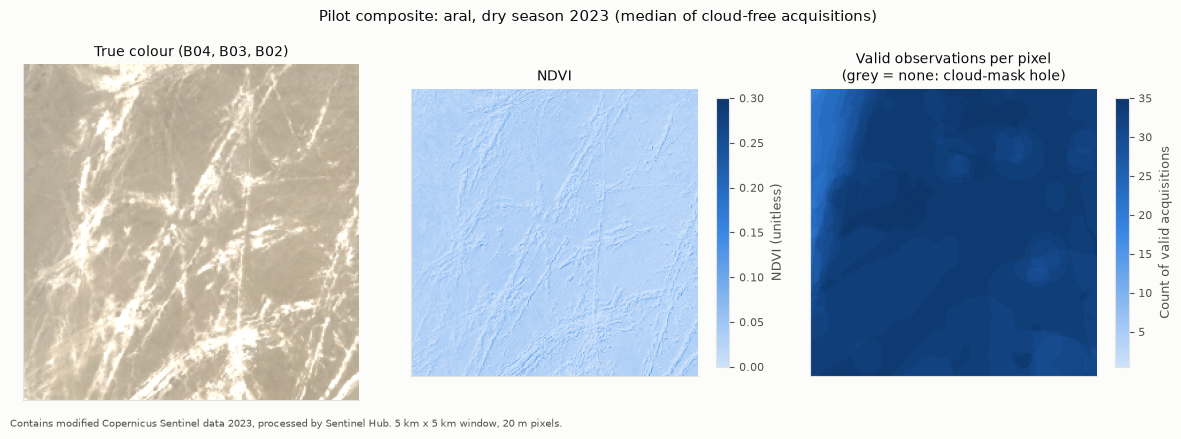

In [62]:
path = composites.get("b10") or composites.get("c6")
if path is not None:
    with rasterio.open(path) as src:
        arr = src.read().astype(float)
        names = list(src.descriptions)
    band = lambda b: arr[names.index(b)] / 10_000
    count = arr[names.index("valid_count")]
    rgb = np.dstack([band("B04"), band("B03"), band("B02")]) * 2.5
    nd = np.where(count > 0, ndvi(band("B08"), band("B04")), np.nan)
    fig = plot_pilot_panels(
        rgb, nd, count,
        f"Pilot composite: {pilot['aoi_id']}, {pilot['season']} season {pilot['year']} (median of cloud-free acquisitions)",
        f"Contains modified Copernicus Sentinel data {pilot['year']}, processed by Sentinel Hub. "
        f"{pilot['window_m'] // 1000} km x {pilot['window_m'] // 1000} km window, {pilot['resolution_m']} m pixels.",
        out_path=FIGURES / "m1_pilot_composite.png",
    )

**Harmonisation (gotcha #1).** Sentinel Hub harmonises the January 2022 processing-baseline change by default. Over the stable erg, each month from February 2022 onward is compared with the same month a year earlier; an unharmonised offset would show as a drop of about 0.1 reflectance in every band, harmonised data as no systematic step.

Harmonisation check passed: True


,band,n_pairs,median_step,ok
0,B02,10,0.001524,True
1,B04,10,-0.005088,True
2,B08,10,-0.000952,True
3,B11,10,-0.004361,True


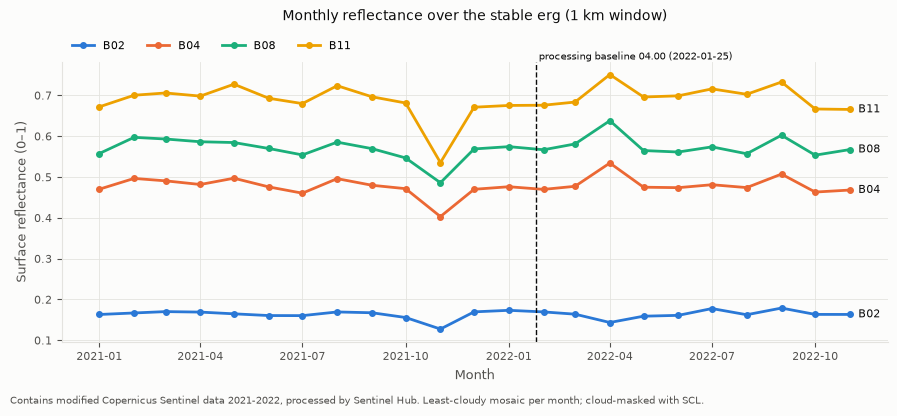

In [63]:
if stats_data is not None:
    series = parse_stats_response(stats_data)
    steps = year_over_year_step(series, h["cutoff"])
    steps["ok"] = steps["median_step"].abs() <= h["tolerance"]
    steps.to_csv(RESULTS / "m1_harmonisation.csv", index=False)
    print("Harmonisation check passed:", harmonisation_ok(steps, h["tolerance"]))
    fig = plot_reflectance_series(
        series, h["cutoff"], f"Monthly reflectance over the stable erg ({h['window_m'] // 1000} km window)",
        f"Contains modified Copernicus Sentinel data {h['start'][:4]}-{h['end'][:4]}, processed by Sentinel Hub. "
        "Least-cloudy mosaic per month; cloud-masked with SCL.",
        out_path=FIGURES / "m1_harmonisation.png",
    )
    display(steps)
else:
    print("No statistics yet (API calls off or not cached).")

### What to check

- **Cache:** re-run the notebook; `API requests made in this run` must be 0.
- **Holes:** `share_zero` of `valid_count` near 0, with no large blank patches in the count panel.
- **Range:** reflectance `p99` ≤ 1 and `share_above_1` near 0 for every band.
- **Harmonisation:** `|median_step|` ≤ 0.02 in every band.
- **Cost:** compare measured PU (header or dashboard) with `projected_pu`; the ratio calibrates the projections in `m1_pu_projection.csv`.

## Scaled extraction (M1-T06)

**Design** (Decision log #51): for each AOI, a centred 10 km × 10 km window inside the validated 20 km square; seasonal median composites with all 10 bands (`b10`) for every complete wet and dry season, and monthly median composites of the five bands the trend indices need; 20 m, 16-bit, only acquisitions with tile cloud cover ≤ 40 %. Indices are computed locally from the reflectances (Decision log #52).

### Window preview (no API calls)

The dashed square is the extraction window, drawn on the true-colour image cached in M1-T02 (dry season of the last study year). If a window misses the landscape it should capture, shift it with `extraction.window_offsets_m` in `config/project.yaml` before running the extraction.

Window offsets in use (m east, m north): {'aral': [2000, 2000], 'urmia': [1000, 1000], 'kubuqi': [-2500, 500]}
Cached images found: {'aral': True, 'ferlo': True, 'fakara': True, 'kubuqi': True, 'urmia': True, 'erg': True}


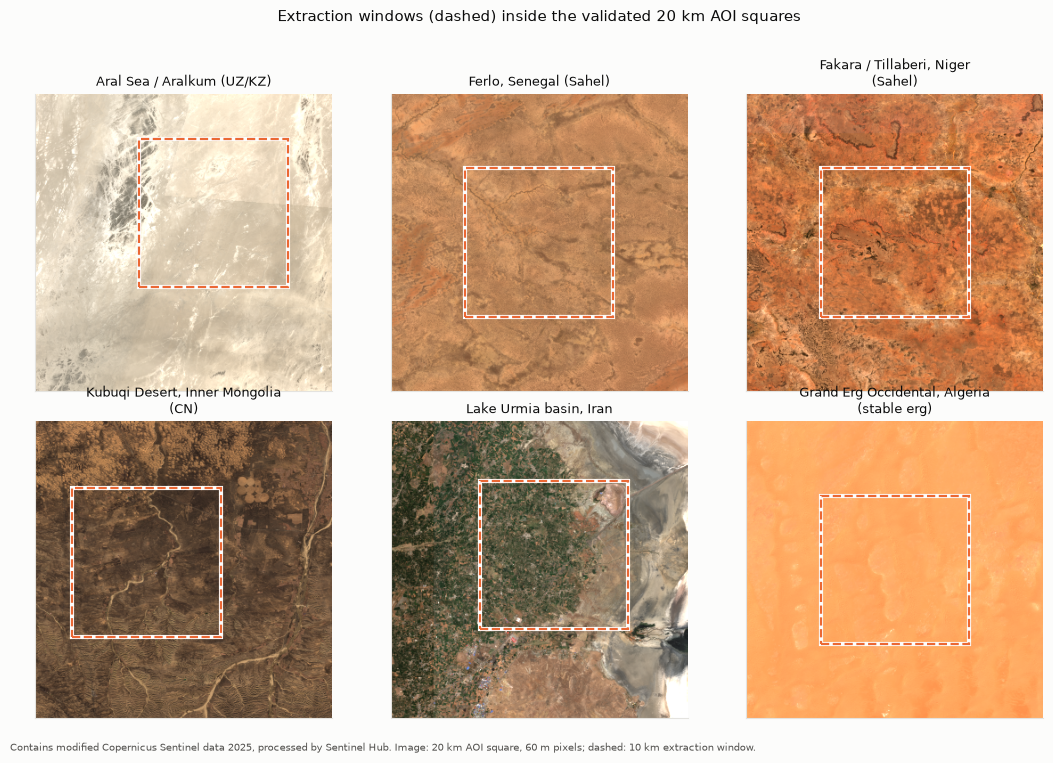

In [64]:
# Re-read the config here so edits to config/project.yaml (e.g. window offsets) apply
# without restarting the kernel; the rest of this section uses this fresh copy.
cfg = load_config()
ext = cfg["extraction"]
study = cfg["periods"]["study"]
offsets = ext.get("window_offsets_m") or {}
print("Window offsets in use (m east, m north):", offsets or "none (all windows centred)")
snap = cfg["aoi_selection"]["snap_m"]
last_year = int(study["end"][:4])
preview, windows, bboxes = {}, {}, {}
for aoi_id, p in aois.items():
    bboxes[aoi_id] = p["bbox_utm"]
    windows[aoi_id] = extraction_window(p["bbox_utm"], ext["window_m"], snap, offsets.get(aoi_id, (0, 0)))
    s_start, s_end = season_window(p["dry_season_months"], last_year)
    img, _, _ = fetch_true_color(cfg, aoi_id, p["bbox_utm"], p["utm_epsg"], s_start, s_end, allow_api=False)
    preview[aoi_id] = img
print("Cached images found:", {k: v is not None for k, v in preview.items()})
fig = plot_window_preview(
    preview, bboxes, windows, {k: p["name"] for k, p in aois.items()},
    f"Contains modified Copernicus Sentinel data {last_year}, processed by Sentinel Hub. "
    f"Image: 20 km AOI square, 60 m pixels; dashed: {ext['window_m'] // 1000} km extraction window.",
    out_path=FIGURES / "m1_extraction_windows.png",
)

### Plan and budget

Projected PU per request uses the rule-based cost model with the pilot's calibration factor and the measured low-cloud effect (as in `01c_feasibility.ipynb`).

In [65]:
pilot_cost = pd.read_csv(RESULTS / "m1_pilot_cost.csv").set_index("request")
unfiltered = [r for r in pilot_cost.index if r.startswith("composite") and "low-cloud" not in r]
calib = pilot_cost.loc[unfiltered, "reported_pu"].sum() / pilot_cost.loc[unfiltered, "projected_pu"].sum()
lc_test = pd.read_csv(RESULTS / "m1_lowcloud_test.csv").iloc[0]
lc_adjust = lc_test["measured_cost_ratio"] / lc_test["low_cloud_share_of_dates"]
av = avail.groupby("aoi_id")[["n_dates", "n_usable_dates"]].mean()
plan = build_plan(
    list(aois.values()), ext, study, snap,
    av["n_dates"].to_dict(), (av["n_usable_dates"] / av["n_dates"]).to_dict(),
    calib=calib, lc_adjust=lc_adjust, offsets=offsets,
)
plan.assign(bands=plan["bands"].map(" ".join), window_utm=plan["window_utm"].map(str)).to_csv(
    RESULTS / "m1_extraction_plan.csv", index=False)
usage_rows = read_usage_log(get_path(cfg, "api_usage_log"))
total_projected = plan["projected_pu"].sum()
fits, left = check_cap(usage_rows, "extraction", total_projected, cfg["quota"]["pu_caps"])
print(f"Plan: {len(plan)} requests ({(plan['product'] == 'seasonal').sum()} seasonal, "
      f"{(plan['product'] == 'monthly').sum()} monthly), projected {total_projected:,.0f} PU")
print(f"Extraction cap {cfg['quota']['pu_caps']['extraction']:,} PU: fits = {fits} "
      f"(left after the plan: {left:,.0f}); reserve {cfg['quota']['pu_caps']['reserve']:,} PU")
plan.groupby(["aoi_id", "product"])["projected_pu"].agg(["count", "sum"]).round(0)

Plan: 585 requests (81 seasonal, 504 monthly), projected 19,203 PU
Extraction cap 20,000 PU: fits = True (left after the plan: 797); reserve 7,000 PU


count     sum
aoi_id product                
aral   monthly      84  1398.0
       seasonal     13  1620.0
erg    monthly      84  1962.0
       seasonal     14  2448.0
fakara monthly      84   939.0
       seasonal     13  1110.0
ferlo  monthly      84   915.0
       seasonal     14  1165.0
kubuqi monthly      84  1500.0
       seasonal     13  1738.0
urmia  monthly      84  1962.0
       seasonal     14  2448.0

### Run (needs approval)

Runs are **resumable**: cached requests are skipped, so the extraction can be done in chunks of `MAX_REQUESTS_THIS_RUN`. A run also stops before it would exceed the remaining extraction cap plus the reserve. Every outcome is appended to `data/raw/download_log.csv`.

In [66]:
RUN_EXTRACTION = False
MAX_REQUESTS_THIS_RUN = ext["max_requests_per_run"]

load_env(cfg)
go_extract = RUN_EXTRACTION and not missing_credentials()
used = sum(r["pu_before"] - r["pu_after"] for r in usage_rows
           if r["budget_category"] in ("extraction", "reserve") and r["pu_before"] is not None and r["pu_after"] is not None)
pu_budget = cfg["quota"]["pu_caps"]["extraction"] + cfg["quota"]["pu_caps"]["reserve"] - used

def download(row, allow_api):
    return download_composite(
        cfg, row["aoi_id"], row["window_utm"], row["epsg"], row["start"], row["end"], ext["resolution_m"],
        bands=row["bands"], label=row["label"], allow_api=allow_api, max_cloud_cover=ext["max_cloud_cover"],
    )

log_path = get_path(cfg, "data_raw") / "download_log.csv"
report = run_plan(plan, download, allow_api=go_extract, max_requests=MAX_REQUESTS_THIS_RUN,
                  pu_budget=pu_budget, attempts=ext["attempts"], backoff_s=ext["retry_backoff_s"],
                  log=lambda entry: append_log(log_path, entry))
print(f"API calls allowed: {go_extract} | downloaded {len(report.downloaded)}, cached {len(report.cached)}, "
      f"failed {len(report.failed)}, not run {len(report.not_run)}")
print(f"Reported PU this run: {report.reported_pu:,.1f}" + (f" | stopped: {report.stopped_reason}" if report.stopped_reason else ""))
print(f"API requests made in this run: {report.api_requests}")

API calls allowed: False | downloaded 0, cached 0, failed 0, not run 585
Reported PU this run: 0.0
API requests made in this run: 0


In [67]:
PU_BEFORE, PU_AFTER = None, None          # settled dashboard balances (Decision log #48)
REQUESTS_BEFORE, REQUESTS_AFTER = None, None

if report.api_requests:
    append_usage(get_path(cfg, "api_usage_log"), make_entry(
        task_id="M1-T06", api="process", budget_category="extraction",
        request_count=report.api_requests + 1,  # + OAuth token
        purpose=f"Extraction run: {report.api_requests} composites, {report.reported_pu:.1f} PU reported",
        pu_before=PU_BEFORE, pu_after=PU_AFTER, requests_before=REQUESTS_BEFORE, requests_after=REQUESTS_AFTER,
    ))
    print("Logged this run.")
else:
    print("No API calls in this run, so nothing new to log.")

No API calls in this run, so nothing new to log.


### Status (acceptance check)

Every planned request must be **present** (cached file with provenance) or listed as **failed with a reason**; total reported PU must be within the cap.

In [68]:
present, costs = set(), {}
for row in plan.to_dict(orient="records"):
    path, _, pu = download(row, False)  # cache lookup only
    if path is not None:
        present.add(row["request_id"])
        costs[row["request_id"]] = pu
failed = {}
if log_path.exists():
    log_df = pd.read_csv(log_path).sort_values("timestamp_utc").groupby("request_id").last()
    failed = {rid: r["error"] for rid, r in log_df.iterrows() if r["status"] == "failed" and rid not in present}
status = plan_status(plan, present, failed)
status.to_csv(RESULTS / "m1_extraction_status.csv", index=False)
summary = status.groupby(["product", "status"]).size().unstack(fill_value=0)
total_reported = sum(v for v in costs.values() if v is not None)
pd.DataFrame([{"requests_planned": len(plan), "present": len(present), "failed": len(failed),
               "missing": len(plan) - len(present) - len(failed), "reported_pu_total": round(total_reported, 1),
               "projected_pu_total": round(total_projected, 1)}]).to_csv(RESULTS / "m1_extraction_cost.csv", index=False)
print(f"Present {len(present)}/{len(plan)}, failed {len(failed)}, reported PU so far {total_reported:,.1f} "
      f"(projected for all: {total_projected:,.0f})")
summary

Present 0/585, failed 0, reported PU so far 0.0 (projected for all: 19,203)


status,missing
product,
monthly,504
seasonal,81
